In [ ]:
!pip -q install ucimlrepo

import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=551)
features = dataset.data.features
targets = dataset.data.targets
original = dataset.data.original

print("=" * 60)
print("1. DATASET DOWNLOAD STATUS")
print("=" * 60)
print("Dataset:", dataset.metadata.get("name", "Gas Turbine CO and NOx"))
print("Features shape:", features.shape if features is not None else "Not provided")
print("Targets shape:", targets.shape if targets is not None else "Not provided")
print("Original data shape:", original.shape if original is not None else "Not provided")

# Standardized bugfix: "YEAR" instead of "year"
expected_columns = [
    "YEAR", "AT", "AP", "AH", "AFDP", "GTEP",
    "TIT", "TAT", "TEY", "CDP", "CO", "NOX"
]

if original is not None and set(expected_columns).issubset(
    set(original.columns.str.strip().str.upper())
):
    df = original.copy()
else:
    available_frames = [
        frame for frame in [features, targets]
        if frame is not None and not frame.empty
    ]
    if not available_frames:
        raise ValueError("UCI returned no usable data frames.")
    df = pd.concat(available_frames, axis=1)
    df = df.loc[:, ~df.columns.duplicated()].copy()

df.columns = df.columns.astype(str).str.strip().str.upper()

print("\n" + "=" * 60)
print("2. COLUMN VERIFICATION")
print("=" * 60)
print("Columns found:", df.columns.tolist())

missing_columns = sorted(set(expected_columns) - set(df.columns))
extra_columns = sorted(set(df.columns) - set(expected_columns))
print("Expected columns missing:", missing_columns)
print("Additional columns:", extra_columns)

print("\n" + "=" * 60)
print("3. DATASET SIZE")
print("=" * 60)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

1. DATASET DOWNLOAD STATUS
Dataset: Gas Turbine CO and NOx Emission Data Set
Features shape: (36733, 12)
Targets shape: Not provided
Original data shape: (36733, 12)

2. COLUMN VERIFICATION
Columns found: ['YEAR', 'AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP', 'CO', 'NOX']
Expected columns missing: []
Additional columns: []

3. DATASET SIZE
Rows: 36733
Columns: 12


,YEAR,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
0,2011,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952
1,2011,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377
2,2011,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776
3,2011,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505
4,2011,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028


In [ ]:
required_columns = [
    "YEAR", "AT", "AP", "AH", "AFDP", "GTEP",
    "TIT", "TAT", "TEY", "CDP", "CO", "NOX"
]

input_columns = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "CDP"]
target_columns = ["TEY", "CO", "NOX"]


missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}. "
        "Do not create replacement columns or artificial year labels."
    )


df = df[required_columns].copy()


for col in required_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Missing values before cleaning:")
print(df.isnull().sum())

if df.isnull().any().any():
    raise ValueError("Missing or non-numeric values found. Inspect them before proceeding.")


df["YEAR"] = df["YEAR"].astype(int)

print("\nYear distribution:")
print(df["YEAR"].value_counts().sort_index())

unexpected_years = sorted(set(df["YEAR"].unique()) - {2011, 2012, 2013, 2014, 2015})

if unexpected_years:
    raise ValueError(f"Unexpected years found: {unexpected_years}")


df = df.sort_values("YEAR", kind="stable").reset_index(drop=True)


train_df = df[df["YEAR"].isin([2011, 2012])].copy()
val_df = df[df["YEAR"] == 2013].copy()
test_df = df[df["YEAR"].isin([2014, 2015])].copy()


X_train = train_df[input_columns].copy()
y_train = train_df[target_columns].copy()

X_val = val_df[input_columns].copy()
y_val = val_df[target_columns].copy()

X_test = test_df[input_columns].copy()
y_test = test_df[target_columns].copy()

print("\nDataset split:")
print(f"Training:   {len(X_train):,} rows | 2011–2012")
print(f"Validation: {len(X_val):,} rows | 2013")
print(f"Testing:    {len(X_test):,} rows | 2014–2015")

print("\nInput shape:", X_train.shape)
print("Output shape:", y_train.shape)

print("\nInput variables:", input_columns)
print("Output variables:", target_columns)

print("\nTraining target statistics:")
display(y_train.describe().round(3))

print("\nTraining input statistics:")
display(X_train.describe().round(3))

assert set(train_df["YEAR"].unique()) == {2011, 2012}
assert set(val_df["YEAR"].unique()) == {2013}
assert set(test_df["YEAR"].unique()) == {2014, 2015}
assert len(train_df) + len(val_df) + len(test_df) == len(df)

print("\nChronological split verified.")

Missing values before cleaning:
YEAR    0
AT      0
AP      0
AH      0
AFDP    0
GTEP    0
TIT     0
TAT     0
TEY     0
CDP     0
CO      0
NOX     0
dtype: int64

Year distribution:
YEAR
2011    7411
2012    7628
2013    7152
2014    7158
2015    7384
Name: count, dtype: int64

Dataset split:
Training:   15,039 rows | 2011–2012
Validation: 7,152 rows | 2013
Testing:    14,542 rows | 2014–2015

Input shape: (15039, 8)
Output shape: (15039, 3)

Input variables: ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'CDP']
Output variables: ['TEY', 'CO', 'NOX']

Training target statistics:


,TEY,CO,NOX
count,15039.000,15039.000,15039.000
mean,134.188,1.972,68.191
std,15.830,2.222,10.471
min,100.170,0.000,27.765
25%,127.985,0.858,61.304
50%,133.780,1.390,66.601
75%,140.895,2.160,73.936
max,174.610,44.103,119.890



Training input statistics:


,AT,AP,AH,AFDP,GTEP,TIT,TAT,CDP
count,15039.000,15039.000,15039.000,15039.000,15039.000,15039.000,15039.000,15039.000
mean,17.764,1013.199,79.124,4.200,25.419,1083.799,545.396,12.102
std,7.574,6.411,13.793,0.760,4.174,16.528,7.867,1.103
min,0.522,985.850,30.344,2.087,17.878,1000.800,512.450,9.904
25%,11.408,1008.900,69.750,3.724,23.294,1079.600,542.170,11.622
50%,18.186,1012.800,82.266,4.186,25.082,1088.700,549.890,12.025
75%,23.862,1016.900,90.044,4.551,27.184,1096.000,550.060,12.578
max,34.929,1034.200,100.200,7.611,37.402,1100.800,550.610,15.081



Chronological split verified.


First 5 rows


,YEAR,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
0,2011,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952
1,2011,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377
2,2011,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776
3,2011,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505
4,2011,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028


Last 5 rows


,YEAR,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
36728,2015,3.6268,1028.5,93.200,3.1661,19.087,1037.0,541.59,109.08,10.411,10.9930,89.172
36729,2015,4.1674,1028.6,94.036,3.1923,19.016,1037.6,542.28,108.79,10.344,11.1440,88.849
36730,2015,5.4820,1028.5,95.219,3.3128,18.857,1038.0,543.48,107.81,10.462,11.4140,96.147
36731,2015,5.8837,1028.7,94.200,3.9831,23.563,1076.9,550.11,131.41,11.771,3.3134,64.738
36732,2015,6.0392,1028.8,94.547,3.8752,22.524,1067.9,548.23,125.41,11.462,11.9810,109.240


Dataset shape: (36733, 12)

Column names:
['YEAR', 'AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP', 'CO', 'NOX']

Data types:
YEAR      int64
AT      float64
AP      float64
AH      float64
AFDP    float64
GTEP    float64
TIT     float64
TAT     float64
TEY     float64
CDP     float64
CO      float64
NOX     float64
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36733 entries, 0 to 36732
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   YEAR    36733 non-null  int64  
 1   AT      36733 non-null  float64
 2   AP      36733 non-null  float64
 3   AH      36733 non-null  float64
 4   AFDP    36733 non-null  float64
 5   GTEP    36733 non-null  float64
 6   TIT     36733 non-null  float64
 7   TAT     36733 non-null  float64
 8   TEY     36733 non-null  float64
 9   CDP     36733 non-null  float64
 10  CO      36733 non-null  float64
 11  NOX     36733 non-null  float64
dtypes

,YEAR,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
count,36733.00,36733.00,36733.00,36733.00,36733.00,36733.00,36733.00,36733.00,36733.00,36733.00,36733.00,36733.00
mean,2012.99,17.71,1013.07,77.87,3.93,25.56,1081.43,546.16,133.51,12.06,2.37,65.29
std,1.42,7.45,6.46,14.46,0.77,4.20,17.54,6.84,15.62,1.09,2.26,11.68
min,2011.00,-6.23,985.85,24.08,2.09,17.70,1000.80,511.04,100.02,9.85,0.00,25.90
25%,2012.00,11.78,1008.80,68.19,3.36,23.13,1071.80,544.72,124.45,11.44,1.18,57.16
50%,2013.00,17.80,1012.60,80.47,3.94,25.10,1085.90,549.88,133.73,11.96,1.71,63.85
75%,2014.00,23.66,1017.00,89.38,4.38,29.06,1097.00,550.04,144.08,12.86,2.84,71.55
max,2015.00,37.10,1036.60,100.20,7.61,40.72,1100.90,550.61,179.50,15.16,44.10,119.91



Missing values:


,0
YEAR,0
AT,0
AP,0
AH,0
AFDP,0
GTEP,0
TIT,0
TAT,0
TEY,0
CDP,0



Duplicate rows: 7

Year-wise records:


,count
YEAR,
2011,7411
2012,7628
2013,7152
2014,7158
2015,7384



Histograms:


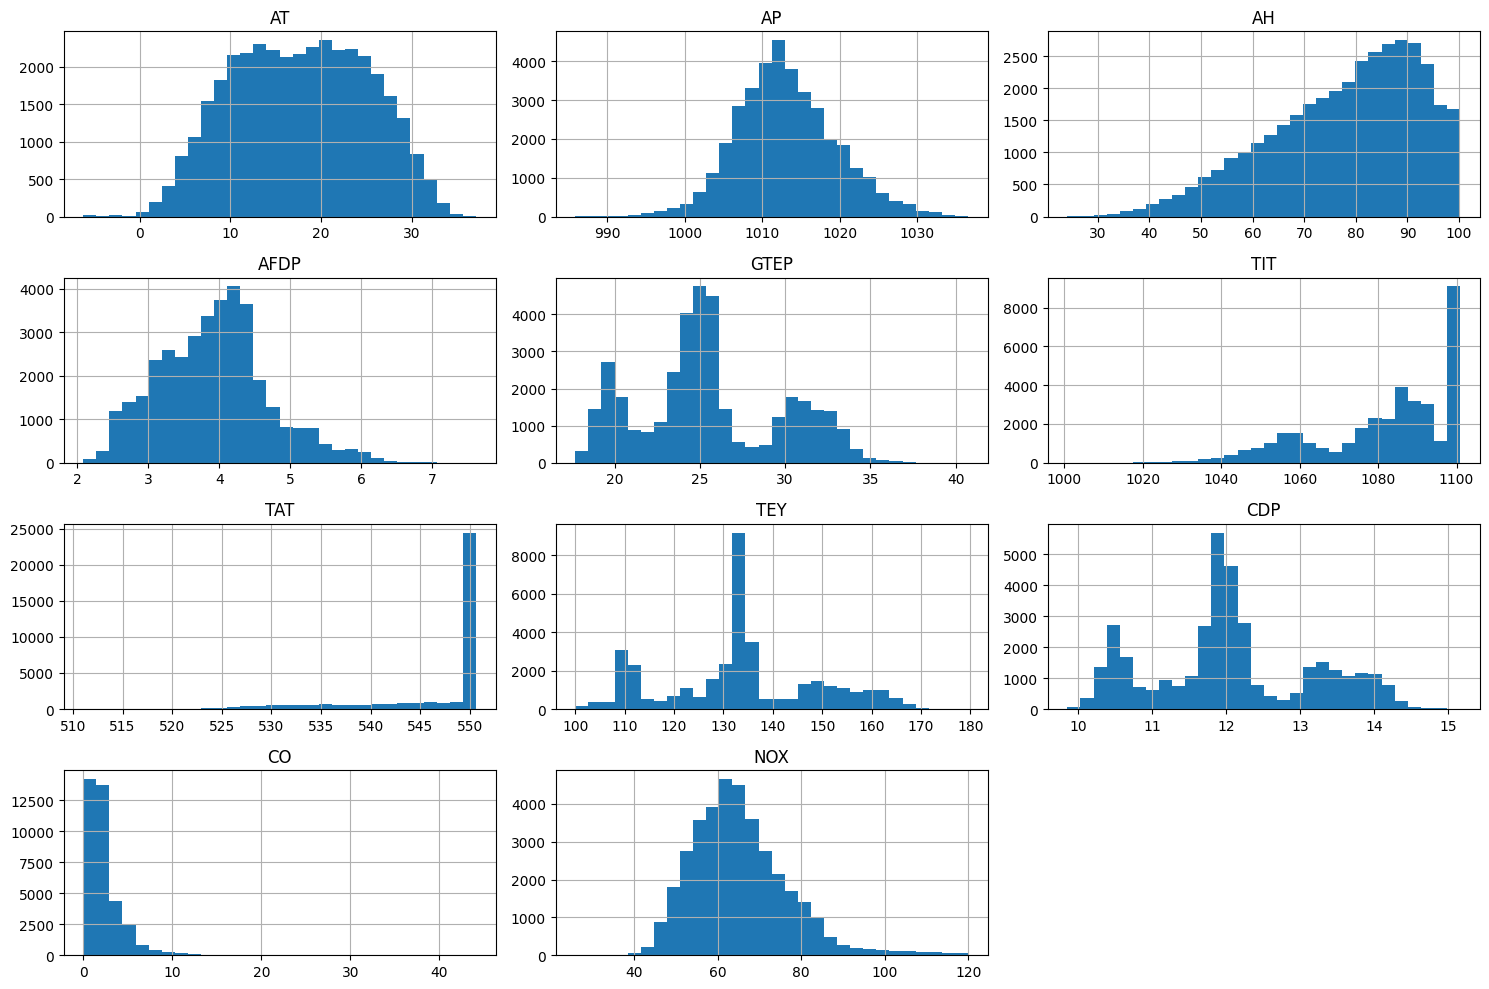


Boxplots:


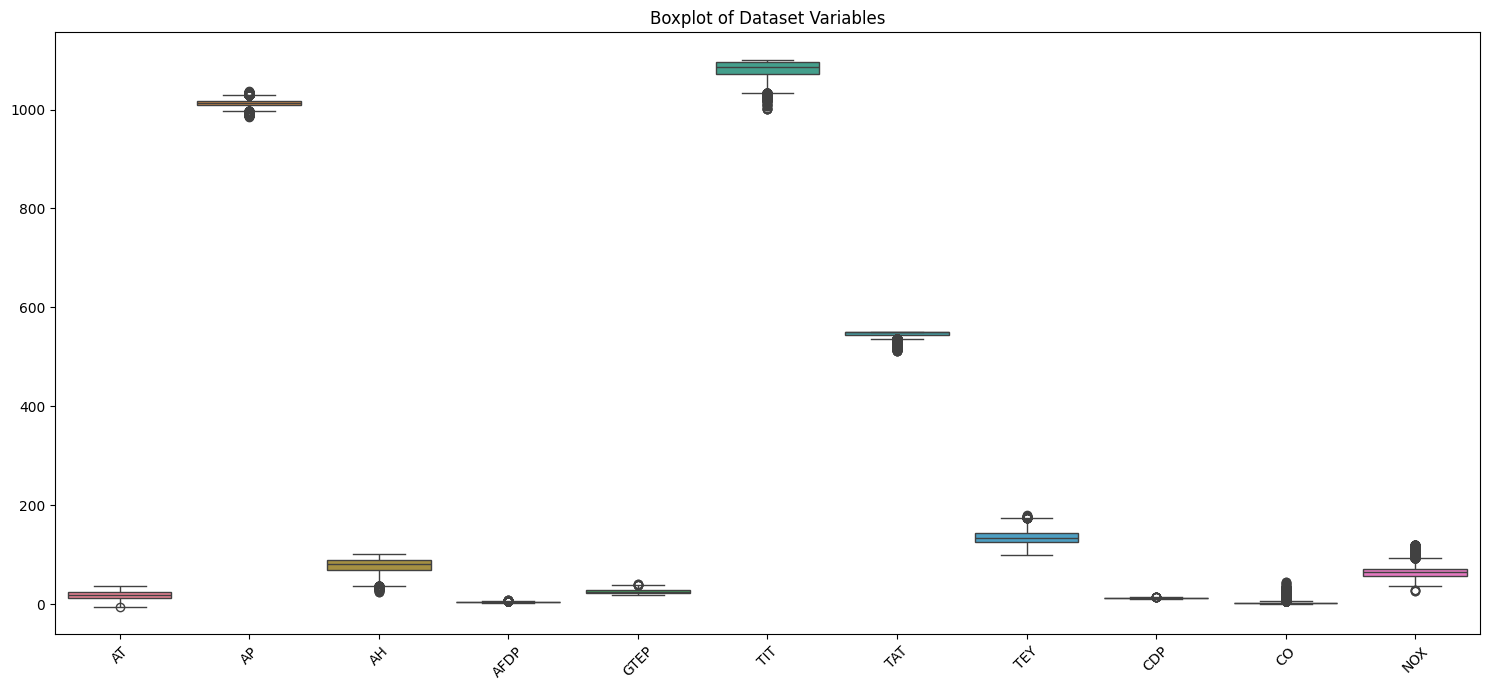

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("First 5 rows")
display(df.head())

print("Last 5 rows")
display(df.tail())

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe().round(2))

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nYear-wise records:")
display(df["YEAR"].value_counts().sort_index())

print("\nHistograms:")
df.drop(columns=["YEAR"]).hist(figsize=(15, 10), bins=30)
plt.tight_layout()
plt.show()

print("\nBoxplots:")
plt.figure(figsize=(15, 7))
sns.boxplot(data=df.drop(columns=["YEAR"]))
plt.xticks(rotation=45)
plt.title("Boxplot of Dataset Variables")
plt.tight_layout()
plt.show()

In [ ]:
# Modified: audit duplicates and report without actual record deletions
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Total records retained:", len(df))
print("Data cleaning check completed.")

Missing values: 0
Duplicate rows: 7
Total records retained: 36733
Data cleaning check completed.


In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Dummy Regression": DummyRegressor(strategy="mean"),
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Decision Tree": DecisionTreeRegressor(random_state=42, min_samples_leaf=2),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    )
}

results = []
validation_predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)
    validation_predictions[name] = predictions

    for i, target in enumerate(target_columns):
        results.append({
            "Model": name,
            "Target": target,
            "MAE": mean_absolute_error(y_val.iloc[:, i], predictions[:, i]),
            "RMSE": np.sqrt(mean_squared_error(y_val.iloc[:, i], predictions[:, i])),
            "R2": r2_score(y_val.iloc[:, i], predictions[:, i])
        })

metrics_df = pd.DataFrame(results)

# Modified: group and display average validation R2 only
model_summary = (
    metrics_df.groupby("Model")["R2"]
    .mean()
    .sort_values(ascending=False)
)

print("Average validation R2:")
display(model_summary.to_frame("Average R2").round(4))

best_model_name = model_summary.index[0]
best_model = models[best_model_name]
print("Selected model:", best_model_name)

Average validation R2:


,Average R2
Model,
Random Forest,0.7546
Decision Tree,0.6550
Linear Regression,0.5702
Dummy Regression,-0.0463


Selected model: Random Forest


In [ ]:
from sklearn.base import clone

X_final_train = pd.concat([X_train, X_val])
y_final_train = pd.concat([y_train, y_val])

final_model = clone(best_model)
final_model.fit(X_final_train, y_final_train)

test_predictions = final_model.predict(X_test)

test_results = []

for i, target in enumerate(target_columns):
    actual = y_test.iloc[:, i]
    predicted = test_predictions[:, i]

    test_results.append({
        "Target": target,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

test_metrics = pd.DataFrame(test_results)

print("Selected model:", best_model_name)
print("\nFinal test performance:")
display(test_metrics.round(4))

print("\nActual vs predicted sample:")
comparison = pd.DataFrame({
    "Actual_TEY": y_test["TEY"].values,
    "Predicted_TEY": test_predictions[:, 0],
    "Actual_CO": y_test["CO"].values,
    "Predicted_CO": test_predictions[:, 1],
    "Actual_NOX": y_test["NOX"].values,
    "Predicted_NOX": test_predictions[:, 2]
})

display(comparison.head(10))

Selected model: Random Forest

Final test performance:


,Target,MAE,RMSE,R2
0,TEY,1.5702,1.9396,0.9832
1,CO,0.9295,1.5520,0.4975
2,NOX,10.8174,12.4304,-0.3812



Actual vs predicted sample:


,Actual_TEY,Predicted_TEY,Actual_CO,Predicted_CO,Actual_NOX,Predicted_NOX
0,126.16,126.035931,1.9157,4.544498,68.292,83.019051
1,126.51,126.046194,2.0596,4.878939,68.610,81.273802
2,126.96,127.146842,2.1621,4.512008,68.324,81.234192
3,127.83,127.083026,2.1214,3.568299,67.619,77.929436
4,126.56,126.027724,2.1549,3.885225,66.499,77.655819
5,128.32,126.128394,2.1566,3.208739,67.005,75.000783
6,127.21,125.199135,1.5995,3.464476,66.593,76.624275
7,126.51,125.501137,1.9358,4.149940,67.891,79.586774
8,127.32,125.409666,1.8884,3.996262,68.946,79.874310
9,126.53,125.285882,1.7925,4.262019,68.853,80.137842


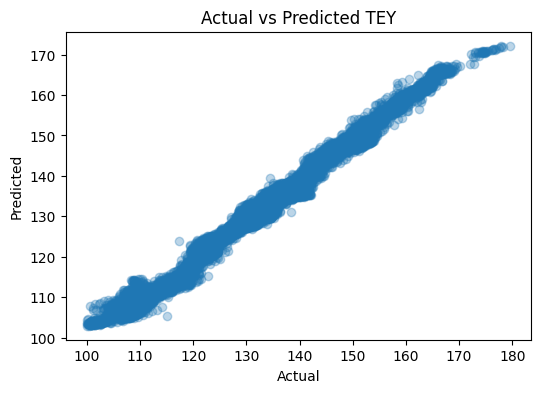

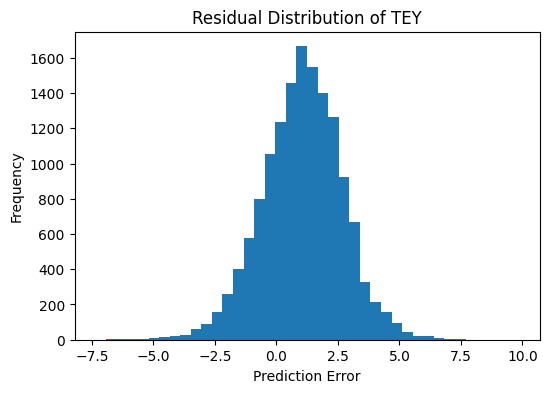

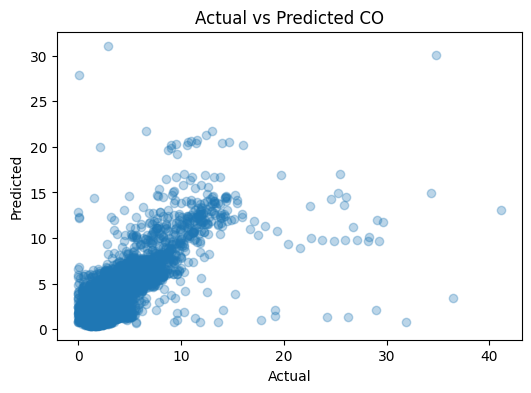

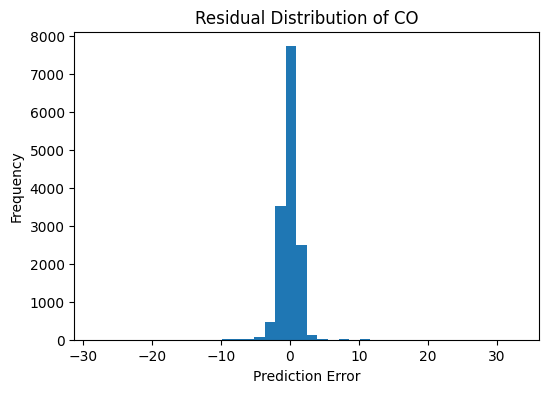

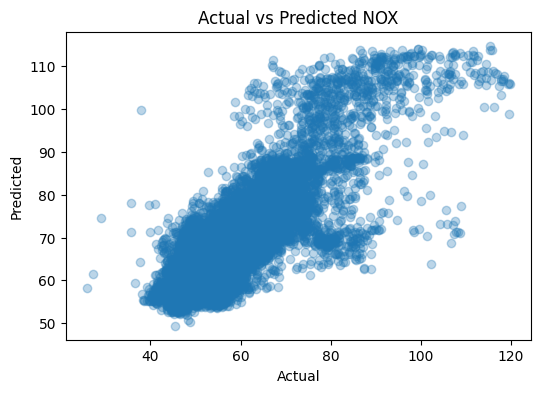

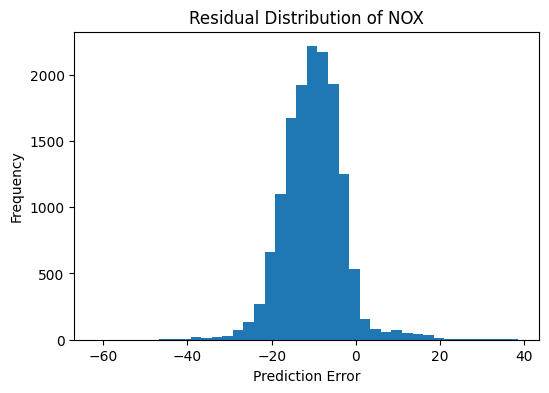

,Feature,Importance
7,CDP,0.660544
0,AT,0.194944
6,TAT,0.054336
5,TIT,0.026863
3,AFDP,0.021910
2,AH,0.018869
4,GTEP,0.011868
1,AP,0.010666


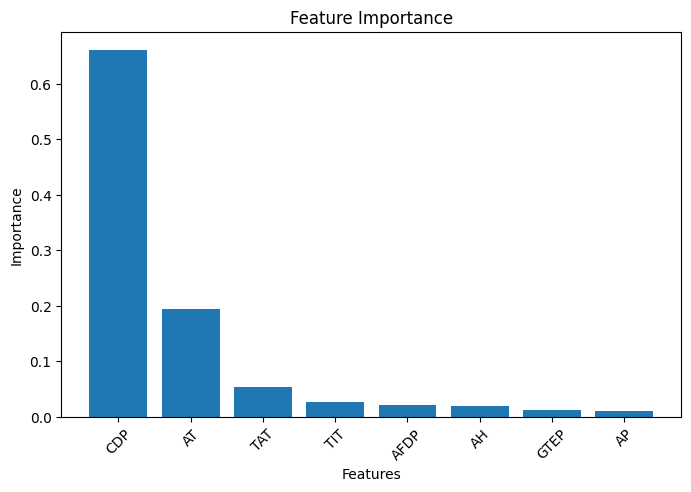

In [ ]:
for i, target in enumerate(target_columns):
    actual = y_test[target].values
    predicted = test_predictions[:, i]

    plt.figure(figsize=(6, 4))
    plt.scatter(actual, predicted, alpha=0.3)
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"Actual vs Predicted {target}")
    plt.show()

    residuals = actual - predicted

    plt.figure(figsize=(6, 4))
    plt.hist(residuals, bins=40)
    plt.xlabel("Prediction Error")
    plt.ylabel("Frequency")
    plt.title(f"Residual Distribution of {target}")
    plt.show()

estimator = final_model

if hasattr(final_model, "named_steps"):
    estimator = final_model.named_steps["model"]

if hasattr(estimator, "feature_importances_"):
    importance = estimator.feature_importances_
elif hasattr(estimator, "coef_"):
    importance = np.mean(np.abs(estimator.coef_), axis=0)
else:
    importance = None

if importance is not None:
    importance_df = pd.DataFrame({
        "Feature": input_columns,
        "Importance": importance
    }).sort_values(by="Importance", ascending=False)

    display(importance_df)

    plt.figure(figsize=(8, 5))
    plt.bar(importance_df["Feature"], importance_df["Importance"])
    plt.xlabel("Features")
    plt.ylabel("Importance")
    plt.title("Feature Importance")
    plt.xticks(rotation=45)
    plt.show()
else:
    print("Feature importance is not available for this model.")

In [ ]:
from scipy.optimize import differential_evolution, NonlinearConstraint
from sklearn.neighbors import NearestNeighbors

process_variables = ["AFDP", "GTEP", "TIT", "TAT", "CDP"]
baseline_input = X_final_train.median()

bounds = [
    (X_final_train[col].quantile(0.05),
     X_final_train[col].quantile(0.95))
    for col in process_variables
]

def predict_condition(values):
    row = baseline_input.copy()
    row[process_variables] = values

    return final_model.predict(
        pd.DataFrame([row], columns=input_columns)
    )[0]

baseline_prediction = predict_condition(
    [baseline_input[col] for col in process_variables]
)

def objective(values):
    prediction = predict_condition(values)
    return prediction[1] / max(abs(baseline_prediction[1]), 1e-6)

def constraints(values):
    prediction = predict_condition(values)

    return [
        prediction[0] - 0.95 * baseline_prediction[0],
        prediction[1],
        prediction[2]
    ]

constraint = NonlinearConstraint(
    constraints,
    [0, 0, 0],
    [np.inf, np.inf, np.inf]
)

optimization_result = differential_evolution(
    objective,
    bounds,
    constraints=(constraint,),
    maxiter=50,
    popsize=8,
    seed=42
)

optimized_values = optimization_result.x
optimized_prediction = predict_condition(optimized_values)

optimization_feasible = (
    optimized_prediction[0] >= 0.95 * baseline_prediction[0] - 1e-6
    and optimized_prediction[1] >= -1e-6
    and optimized_prediction[2] >= -1e-6
)

comparison_results = pd.DataFrame({
    "Output": target_columns,
    "Before Optimization": baseline_prediction,
    "After Optimization": optimized_prediction
})

comparison_results["Change (%)"] = (
    (comparison_results["After Optimization"] -
     comparison_results["Before Optimization"])
    / comparison_results["Before Optimization"].abs().clip(lower=1e-6)
) * 100

print("Optimizer successful:", optimization_result.success)
print("Constraint feasible:", optimization_feasible)

print("\nOptimized parameters:")
display(pd.DataFrame({
    "Parameter": process_variables,
    "Optimized Value": optimized_values
}))

print("\nBaseline vs optimized predictions:")
display(comparison_results.round(4))

scaler_check = StandardScaler()

train_scaled = scaler_check.fit_transform(
    X_final_train[process_variables]
)

candidate_scaled = scaler_check.transform(
    pd.DataFrame([optimized_values], columns=process_variables)
)

neighbor_model = NearestNeighbors(n_neighbors=2)
neighbor_model.fit(train_scaled)

historical_distances = neighbor_model.kneighbors(train_scaled)[0][:, 1]
candidate_distance = neighbor_model.kneighbors(candidate_scaled)[0][0, 0]
distance_limit = np.quantile(historical_distances, 0.95)

print("\nNearest historical distance:", round(candidate_distance, 4))
print("95th percentile reference:", round(distance_limit, 4))

if candidate_distance > distance_limit:
    print("Warning: Candidate is unusual compared with historical conditions.")
else:
    print("Candidate is relatively close to historical conditions.")

Optimizer successful: True
Constraint feasible: True

Optimized parameters:


,Parameter,Optimized Value
0,AFDP,2.956825
1,GTEP,30.803459
2,TIT,1090.571716
3,TAT,531.359271
4,CDP,13.851531



Baseline vs optimized predictions:


,Output,Before Optimization,After Optimization,Change (%)
0,TEY,133.7608,158.0924,18.1904
1,CO,1.6241,0.5563,-65.7469
2,NOX,68.0886,57.1408,-16.0787



Nearest historical distance: 0.7859
95th percentile reference: 0.1255


In [ ]:
def predict_emissions(AT, AP, AH, AFDP, GTEP, TIT, TAT, CDP):
    input_data = pd.DataFrame([[
        AT, AP, AH, AFDP, GTEP, TIT, TAT, CDP
    ]], columns=input_columns)

    predictions = final_model.predict(input_data)[0]

    print("Predicted Turbine Energy Yield:", round(predictions[0], 3))
    print("Predicted CO Emissions:", round(predictions[1], 3))
    print("Predicted NOX Emissions:", round(predictions[2], 3))

predict_emissions(
    15, 1013, 60, 3, 25, 1080, 550, 10
)

Predicted Turbine Energy Yield: 120.622
Predicted CO Emissions: 2.929
Predicted NOX Emissions: 73.144


In [ ]:
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_final_train, y_final_train)

dummy_predictions = dummy_model.predict(X_test)

comparison = []

for name, predictions in [
    ("Dummy Regressor", dummy_predictions),
    (best_model_name, test_predictions)
]:
    for i, target in enumerate(target_columns):
        comparison.append({
            "Model": name,
            "Target": target,
            "MAE": mean_absolute_error(y_test.iloc[:, i], predictions[:, i]),
            "RMSE": np.sqrt(mean_squared_error(y_test.iloc[:, i], predictions[:, i])),
            "R2": r2_score(y_test.iloc[:, i], predictions[:, i])
        })

baseline_test_comparison = pd.DataFrame(comparison)
display(baseline_test_comparison.round(4))

,Model,Target,MAE,RMSE,R2
0,Dummy Regressor,TEY,11.7062,14.9756,-0.0000
1,Dummy Regressor,CO,1.2297,2.2255,-0.0333
2,Dummy Regressor,NOX,11.9136,13.7584,-0.6921
3,Random Forest,TEY,1.5702,1.9396,0.9832
4,Random Forest,CO,0.9295,1.5520,0.4975
5,Random Forest,NOX,10.8174,12.4304,-0.3812


In [ ]:
print("Optimizer success:", optimization_result.success)
print("Optimizer message:", optimization_result.message)
print("Optimization objective:", optimization_result.fun)
print("Constraint feasible:", optimization_feasible)

print("\nBaseline TEY:", baseline_prediction[0])
print("Minimum required TEY:", 0.95 * baseline_prediction[0])
print("Optimized TEY:", optimized_prediction[0])

print("\nBaseline CO:", baseline_prediction[1])
print("Optimized CO:", optimized_prediction[1])

print("\nBaseline NOX:", baseline_prediction[2])
print("Optimized NOX:", optimized_prediction[2])

Optimizer success: True
Optimizer message: Optimization terminated successfully.
Optimization objective: 0.3425307503180313
Constraint feasible: True

Baseline TEY: 133.76080934523807
Minimum required TEY: 127.07276887797616
Optimized TEY: 158.09240721861477

Baseline CO: 1.6240947257142857
Optimized CO: 0.5563023849864716

Baseline NOX: 68.08862167857141
Optimized NOX: 57.140835380772025


In [ ]:
print("NOX distribution by year")

display(
    df.groupby("YEAR")["NOX"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(3)
)

train_nox_predictions = best_model.predict(X_train)[:, 2]
val_nox_predictions = validation_predictions[best_model_name][:, 2]

performance = []

for name, actual, predicted in [
    ("Training", y_train["NOX"], train_nox_predictions),
    ("Validation", y_val["NOX"], val_nox_predictions)
]:
    performance.append({
        "Dataset": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

test_nox = test_df[["YEAR"]].copy()
test_nox["Actual"] = y_test["NOX"].values
test_nox["Predicted"] = test_predictions[:, 2]

for year, group in test_nox.groupby("YEAR"):
    performance.append({
        "Dataset": str(year),
        "MAE": mean_absolute_error(group["Actual"], group["Predicted"]),
        "RMSE": np.sqrt(mean_squared_error(group["Actual"], group["Predicted"])),
        "R2": r2_score(group["Actual"], group["Predicted"])
    })

print("\nNOX model performance:")
display(pd.DataFrame(performance).round(4))

train_period = df[df["YEAR"].isin([2011, 2012, 2013])]
test_period = df[df["YEAR"].isin([2014, 2015])]

drift = pd.DataFrame({
    "Training Mean": train_period[input_columns + ["NOX"]].mean(),
    "Test Mean": test_period[input_columns + ["NOX"]].mean(),
    "Training Std": train_period[input_columns + ["NOX"]].std()
})

drift["Mean Shift (Training Std)"] = (
    (drift["Test Mean"] - drift["Training Mean"]) / drift["Training Std"]
)

print("\nTraining vs test distribution:")
display(drift.round(3))

NOX distribution by year


,count,mean,std,min,max
YEAR,,,,,
2011,7411,67.575,10.683,27.765,119.32
2012,7628,68.789,10.225,41.777,119.89
2013,7152,70.008,12.048,43.198,119.91
2014,7158,60.067,9.972,27.183,118.47
2015,7384,59.891,11.132,25.905,119.68



NOX model performance:


,Dataset,MAE,RMSE,R2
0,Training,0.9896,1.6633,0.9748
1,Validation,5.6503,7.5913,0.6029
2,2014,9.1876,10.8109,-0.1755
3,2015,12.3973,13.8204,-0.5414



Training vs test distribution:


,Training Mean,Test Mean,Training Std,Mean Shift (Training Std)
AT,17.712,17.713,7.353,0.000
AP,1012.813,1013.463,6.397,0.102
AH,79.555,75.291,13.915,-0.306
AFDP,4.038,3.754,0.810,-0.350
GTEP,25.318,25.939,4.234,0.147
TIT,1083.080,1078.907,16.841,-0.248
TAT,545.520,547.133,7.709,0.209
CDP,12.060,12.061,1.114,0.001
NOX,68.777,59.977,11.036,-0.797


In [ ]:
# Export the trained model and dashboard metadata as one artifact.
# Run this cell only after all previous notebook cells have completed.

import joblib
import sklearn
import sys
import os
from google.colab import files

# Input defaults and allowed ranges from the final training data.
input_defaults = {
    col: float(X_final_train[col].median())
    for col in input_columns
}

input_ranges = {
    col: [
        float(X_final_train[col].quantile(0.05)),
        float(X_final_train[col].quantile(0.95))
    ]
    for col in input_columns
}

# Package the trained model and all information used by the dashboard.
bundle = {
    "model": final_model,
    "input_columns": list(input_columns),
    "target_columns": list(target_columns),
    "input_defaults": input_defaults,
    "input_ranges": input_ranges,
    "selected_model": str(best_model_name),
    "validation_model_summary": {
        str(k): float(v) for k, v in model_summary.to_dict().items()
    },
    "test_metrics": test_metrics.to_dict(orient="records"),
    "baseline_test_comparison": baseline_test_comparison.to_dict(orient="records"),
    "feature_importance": importance_df[["Feature", "Importance"]].to_dict(orient="records"),
    "optimization": {
        "success": bool(optimization_result.success),
        "feasible": bool(optimization_feasible),
        "baseline": {
            str(k): float(v)
            for k, v in zip(target_columns, baseline_prediction)
        },
        "optimized": {
            str(k): float(v)
            for k, v in zip(target_columns, optimized_prediction)
        },
        "parameters": [
            {"Parameter": str(name), "Optimized Value": float(value)}
            for name, value in zip(process_variables, optimized_values)
        ],
        "candidate_distance": float(candidate_distance),
        "distance_limit": float(distance_limit),
        "unusual_candidate": bool(candidate_distance > distance_limit),
    },
    "runtime": {
        "python": sys.version.split()[0],
        "sklearn": sklearn.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "joblib": joblib.__version__,
    },
}

artifact_name = "gas_turbine_artifacts.joblib"
joblib.dump(bundle, artifact_name, compress=3)

print("MODEL ARTIFACT EXPORTED")
print("Selected model:", bundle["selected_model"])
print("Inputs:", bundle["input_columns"])
print("Outputs:", bundle["target_columns"])
print("Runtime versions:", bundle["runtime"])
print("Artifact size (MB):", round(os.path.getsize(artifact_name) / 1024 / 1024, 2))

files.download(artifact_name)
